
CUSTOMER CHURN DATASET
   Tenure  MonthlyCharges  DataUsage  SupportTickets  Churn
0      52              36      64.16               8      0
1      15              37      26.43               5      1
2      72              94      63.57               0      0
3      61              86       6.79               6      1
4      21              96      15.04               6      1

DATASET SHAPE
(1000, 5)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Tenure          1000 non-null   int64  
 1   MonthlyCharges  1000 non-null   int64  
 2   DataUsage       1000 non-null   float64
 3   SupportTickets  1000 non-null   int64  
 4   Churn           1000 non-null   int64  
dtypes: float64(1), int64(4)
memory usage: 39.2 KB

MISSING VALUES
Tenure            0
MonthlyCharges    0
DataUsage         0
SupportTickets    0
Chu

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)


MODEL COMPILED SUCCESSFULLY
Epoch 1/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - accuracy: 0.2750 - loss: 0.9003 - val_accuracy: 0.3125 - val_loss: 0.8272
Epoch 2/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - accuracy: 0.3234 - loss: 0.7981 - val_accuracy: 0.3187 - val_loss: 0.7554
Epoch 3/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - accuracy: 0.4187 - loss: 0.7267 - val_accuracy: 0.4437 - val_loss: 0.7052
Epoch 4/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.5500 - loss: 0.6763 - val_accuracy: 0.5750 - val_loss: 0.6688
Epoch 5/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - accuracy: 0.6844 - loss: 0.6372 - val_accuracy: 0.6250 - val_loss: 0.6403
Epoch 6/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.7641 - loss: 0.6034 - val_accuracy: 0.6375 - val_loss: 0.6165
Epoch 7/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.7781 - loss: 0.5721 - val_accuracy: 0.6687 - val_loss: 0.5956
Epoch 8/100
20/20 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - accuracy: 0.7937 - lo

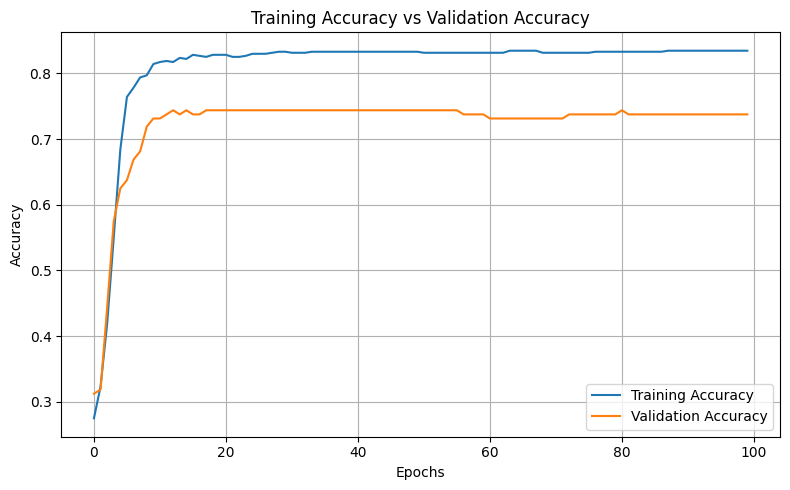

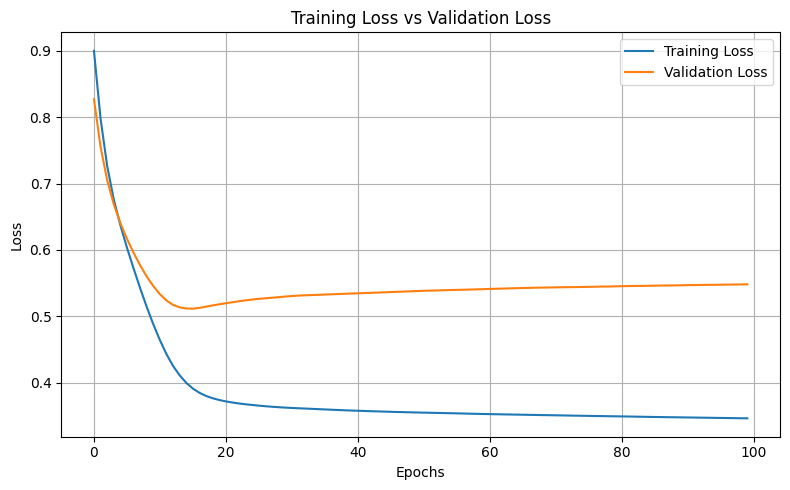


NEW CUSTOMER PREDICTION
   Tenure  MonthlyCharges  DataUsage  SupportTickets
0       6             110         10               8
Churn Probability: 99.95 %
Predicted Status: Customer Likely to Leave

MODEL SAVED SUCCESSFULLY
Saved model: customer_churn_model.keras
Saved scaler: customer_churn_scaler.pkl

CUSTOMER CHURN PREDICTION PROJECT COMPLETED


In [1]:

# ==========================================================
# AI-BASED CUSTOMER CHURN PREDICTION USING ANN
# Technologies: NumPy, Pandas, Scikit-Learn, TensorFlow/Keras
# ==========================================================


# STEP 1: IMPORT LIBRARIES

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


# Set random seed for reproducible results
np.random.seed(42)
tf.random.set_seed(42)


# STEP 2: GENERATE DATASET

n = 1000

tenure = np.random.randint(1, 73, n)
monthly_charges = np.random.randint(30, 121, n)
data_usage = np.round(np.random.uniform(1, 100, n), 2)
support_tickets = np.random.randint(0, 11, n)

# Generate churn probability based on customer behavior
score = (
    1.0
    - tenure * 0.05
    + (monthly_charges - 70) * 0.025
    - (data_usage - 50) * 0.015
    + support_tickets * 0.4
)

churn_probability = 1 / (1 + np.exp(-score))

# Generate the target: 0 = Stays, 1 = Leaves
churn = np.random.binomial(1, churn_probability)

data = {
    "Tenure": tenure,
    "MonthlyCharges": monthly_charges,
    "DataUsage": data_usage,
    "SupportTickets": support_tickets,
    "Churn": churn
}

df = pd.DataFrame(data)

print("\nCUSTOMER CHURN DATASET")
print(df.head())

print("\nDATASET SHAPE")
print(df.shape)

print("\nDATASET INFORMATION")
df.info()

print("\nMISSING VALUES")
print(df.isnull().sum())

print("\nCHURN DISTRIBUTION")
print(df["Churn"].value_counts())


# STEP 3: SEPARATE FEATURES AND TARGET

X = df[[
    "Tenure",
    "MonthlyCharges",
    "DataUsage",
    "SupportTickets"
]]

y = df["Churn"]

print("\nFEATURES (X)")
print(X.head())

print("\nTARGET (y)")
print(y.head())


# STEP 4: TRAIN-TEST SPLIT

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\nTRAINING DATA SHAPE:", X_train.shape)
print("TESTING DATA SHAPE:", X_test.shape)


# STEP 5: FEATURE SCALING

scaler = StandardScaler()

# Fit scaler only on training data to avoid data leakage
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nFEATURE SCALING COMPLETED")
print("Scaled training data:")
print(X_train[:5])


# STEP 6: BUILD ANN MODEL

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(4,)),

    tf.keras.layers.Dense(16, activation="relu"),

    tf.keras.layers.Dense(8, activation="relu"),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

print("\nANN MODEL SUMMARY")
model.summary()


# STEP 7: COMPILE MODEL

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nMODEL COMPILED SUCCESSFULLY")


# STEP 8: TRAIN THE MODEL

history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)


# STEP 9: EVALUATE THE MODEL

test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

print("\nMODEL EVALUATION")
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")
print("Test Loss:", round(test_loss, 4))


# STEP 10: PREDICT TEST DATA

y_probability = model.predict(X_test, verbose=0)

# Probability >= 0.5 means predicted churn = 1
y_pred = (y_probability >= 0.5).astype(int).flatten()

print("\nPREDICTION ACCURACY")
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nCONFUSION MATRIX")
print(confusion_matrix(y_test, y_pred))

print("\nCLASSIFICATION REPORT")
print(classification_report(y_test, y_pred, zero_division=0))


# STEP 11: GRAPH - TRAINING VS VALIDATION ACCURACY

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training Accuracy vs Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# STEP 12: GRAPH - TRAINING VS VALIDATION LOSS

plt.figure(figsize=(8, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training Loss vs Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


# STEP 13: PREDICT A NEW CUSTOMER

# Example customer:
# Tenure = 6 months
# Monthly Charges = Rs. 110
# Data Usage = 10 GB
# Support Tickets = 8

new_customer = pd.DataFrame({
    "Tenure": [6],
    "MonthlyCharges": [110],
    "DataUsage": [10],
    "SupportTickets": [8]
})

# Apply the same scaler used during training
new_customer_scaled = scaler.transform(new_customer)

# Predict churn probability
new_probability = model.predict(
    new_customer_scaled,
    verbose=0
)[0][0]

# Convert probability into a class
if new_probability >= 0.5:
    prediction = "Customer Likely to Leave"
else:
    prediction = "Customer Likely to Stay"

print("\nNEW CUSTOMER PREDICTION")
print(new_customer)

print("Churn Probability:", round(float(new_probability) * 100, 2), "%")
print("Predicted Status:", prediction)


# STEP 14: SAVE TRAINED MODEL AND SCALER

model.save("customer_churn_model.keras")

with open("customer_churn_scaler.pkl", "wb") as file:
    pickle.dump(scaler, file)

print("\nMODEL SAVED SUCCESSFULLY")
print("Saved model: customer_churn_model.keras")
print("Saved scaler: customer_churn_scaler.pkl")


# STEP 15: PROJECT COMPLETED

print("\n" + "=" * 45)
print("CUSTOMER CHURN PREDICTION PROJECT COMPLETED")
print("=" * 45)